# Used Car Listings: Pandas Data Analysis & EDA

Dataset: `car_prices.csv` (used car auction listings). All tasks from the problem statement are answered below, in order, with the written insight directly after each result.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', rc={'axes.spines.top': False, 'axes.spines.right': False})
BLUE = '#2a78d6'; GREY = '#b9b8b2'
DATA_PATH = 'Dataset/car_prices.csv'

## 1. Data Ingestion & Quality Profiling
### 1.1 Load & inspect

In [2]:
df = pd.read_csv(DATA_PATH)
df.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [3]:
df.info()
print('\nRecord count:', len(df))

<class 'pandas.DataFrame'>
RangeIndex: 558837 entries, 0 to 558836
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   year          558837 non-null  int64  
 1   make          548536 non-null  str    
 2   model         548438 non-null  str    
 3   trim          548186 non-null  str    
 4   body          545642 non-null  str    
 5   transmission  493485 non-null  str    
 6   vin           558833 non-null  str    
 7   state         558837 non-null  str    
 8   condition     547017 non-null  float64
 9   odometer      558743 non-null  float64
 10  color         558088 non-null  str    
 11  interior      558088 non-null  str    
 12  seller        558837 non-null  str    
 13  mmr           558799 non-null  float64
 14  sellingprice  558825 non-null  float64
 15  saledate      558825 non-null  str    
dtypes: float64(4), int64(1), str(11)
memory usage: 68.2 MB

Record count: 558837


### 1.2 Understanding the data structure

In [4]:
print('Shape (rows, columns):', df.shape)
print()
print(df.dtypes)

Shape (rows, columns): (558837, 16)

year              int64
make                str
model               str
trim                str
body                str
transmission        str
vin                 str
state               str
condition       float64
odometer        float64
color               str
interior            str
seller              str
mmr             float64
sellingprice    float64
saledate            str
dtype: object


### 1.3 Missing values & anomaly detection

In [5]:
nulls = df.isna().sum().rename('null_count').to_frame()
nulls['null_pct'] = (nulls['null_count'] / len(df) * 100).round(2)
nulls.sort_values('null_count', ascending=False)

,null_count,null_pct
transmission,65352,11.69
body,13195,2.36
condition,11820,2.12
trim,10651,1.91
model,10399,1.86
make,10301,1.84
color,749,0.13
interior,749,0.13
odometer,94,0.02
mmr,38,0.01


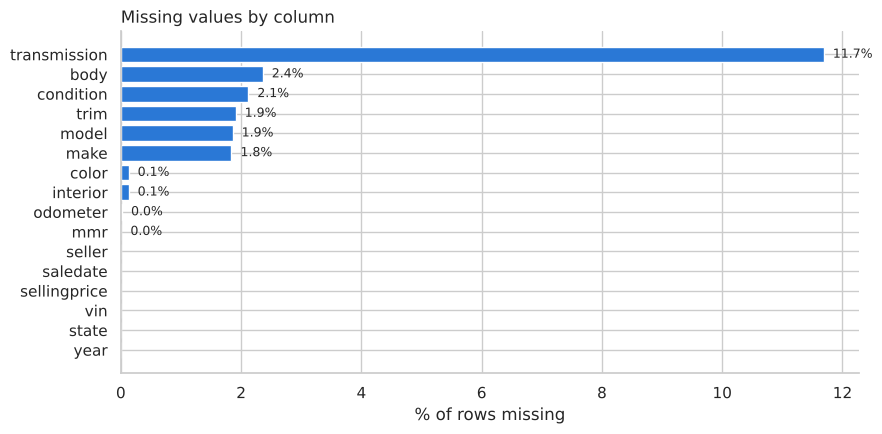

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
n = nulls.sort_values('null_pct')
ax.barh(n.index, n['null_pct'], color=BLUE)
for i, v in enumerate(n['null_pct']):
    if v > 0: ax.text(v + 0.15, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlabel('% of rows missing'); ax.set_title('Missing values by column', loc='left')
plt.tight_layout(); plt.show()

**Anomalies found beyond nulls.** Before choosing a null strategy I checked for malformed values:
- A small group of rows is **column-shifted** (for example `color` holds a number such as `4802` and `state` holds a VIN). These rows cannot be repaired reliably, so they are removed.
- `make`, `body` and `transmission` mix upper and lower case and aliases (`vw` / `Volkswagen`, `ford tk` / `Ford`), which would split one brand into several.
- `color` and `interior` use `—` as a placeholder for "unknown".
- `odometer = 999999` is a placeholder, not a real reading.

In [7]:
shifted = pd.to_numeric(df['color'], errors='coerce').notna()
print('Column-shifted rows:', shifted.sum())
print('Odometer == 999999 :', (df['odometer'] == 999999).sum())
print("Placeholder '—' in color / interior:", (df['color'] == '—').sum(), '/', (df['interior'] == '—').sum())
print('Selling price <= $100:', (df['sellingprice'] <= 100).sum())
print('Distinct make labels (raw):', df['make'].nunique())

Column-shifted rows: 26
Odometer == 999999 : 72
Placeholder '—' in color / interior: 24685 / 17077
Selling price <= $100: 23
Distinct make labels (raw): 96


In [8]:
# --- cleaning ---
df = df.loc[~shifted].copy()

# standardise text
for c in ['make', 'model', 'trim', 'body', 'transmission', 'color', 'interior', 'state']:
    df[c] = df[c].astype('string').str.strip().str.lower()
df[['color', 'interior']] = df[['color', 'interior']].replace('—', pd.NA)

make_fix = {'vw': 'volkswagen', 'mercedes': 'mercedes-benz', 'mercedes-b': 'mercedes-benz', 'landrover': 'land rover',
            'chev truck': 'chevrolet', 'ford tk': 'ford', 'ford truck': 'ford', 'dodge tk': 'dodge',
            'gmc truck': 'gmc', 'hyundai tk': 'hyundai', 'mazda tk': 'mazda'}
df['make'] = df['make'].replace(make_fix)

# placeholder odometer -> missing, so it is imputed like any other gap
df.loc[df['odometer'] >= 999999, 'odometer'] = np.nan

# selling price is the target: a row without it is unusable
df = df.dropna(subset=['sellingprice'])
print('Rows after removing shifted rows and rows with no selling price:', len(df))

Rows after removing shifted rows and rows with no selling price: 558799


**Null-handling strategy (by type and share of nulls)**

| Column | Type | Nulls | Strategy | Why |
|---|---|---|---|---|
| `sellingprice` | numeric | <0.01% | drop rows | it is the target; imputing it would invent answers |
| `odometer`, `mmr` | numeric | <0.1% | fill with median of the same model year (`mmr`: overall median) | skewed numbers, so median not mean; mileage depends on age |
| `condition` | numeric | ~2% | fill with overall median | skewed, small share, no better predictor |
| `make`, `model`, `trim`, `body` | text | ~2% | fill with `unknown` | under 3%, but dropping would remove valid price data |
| `color`, `interior` | text | ~0.1% + `—` placeholders | fill with `unknown` | a real "unknown" category |
| `transmission` | text | ~12% | fill with `unknown` | too many rows to drop; guessing the mode would bias results |

In [9]:
df['odometer'] = df['odometer'].fillna(df.groupby('year')['odometer'].transform('median'))
df['odometer'] = df['odometer'].fillna(df['odometer'].median())
df['mmr'] = df['mmr'].fillna(df['mmr'].median())
df['condition'] = df['condition'].fillna(df['condition'].median())
for c in ['make', 'model', 'trim', 'body', 'transmission', 'color', 'interior']:
    df[c] = df[c].fillna('unknown')
# the few remaining non-standard transmission labels are body types entered in the wrong column
df.loc[~df['transmission'].isin(['automatic', 'manual', 'unknown']), 'transmission'] = 'unknown'

print('Remaining nulls:', int(df.isna().sum().sum()))

Remaining nulls: 0


In [10]:
dups = df.duplicated().sum()
print('Duplicate records:', dups)
df = df.drop_duplicates()
print('Rows after duplicate removal:', len(df), '| duplicates now:', df.duplicated().sum())

Duplicate records: 0


Rows after duplicate removal: 558799 | duplicates now: 0


**Findings.**
- **Nulls:** `transmission` is the only column with a large gap (11.7%, 65,352 rows). `body`, `condition`, `trim`, `model` and `make` each miss about 2%. Every other column misses 0.13% or less.
- **Rows removed:** 26 column-shifted rows and 12 rows with no selling price, leaving **558,799 records**.
- **Duplicates:** none, so nothing was deleted.
- **Standardising text** cut the make labels from 96 to 56, because spelling variants such as `vw` and `Volkswagen` are now one brand.

## 2. DataFrame Queries

### 2.1 Average, minimum and maximum car price

In [11]:
df['sellingprice'].agg(['mean', 'min', 'max']).round(2)

mean     13611.36
min          1.00
max     230000.00
Name: sellingprice, dtype: float64

**Average $13,611.36, minimum $1, maximum $230,000** (median $12,100). The extremes need care: 23 cars sold for $100 or less, and the $230,000 maximum is a Ford Escape whose market value (mmr) is only $22,800, so it is almost certainly a typing error. I kept them because they are in the source data, and flag them here. The mean is above the median because a small number of luxury cars pull it up.

### 2.2 Unique colors

In [12]:
colors = sorted(df['color'].unique())
print(len(colors), 'unique colors:'); print(colors)

20 unique colors:
['beige', 'black', 'blue', 'brown', 'burgundy', 'charcoal', 'gold', 'gray', 'green', 'lime', 'off-white', 'orange', 'pink', 'purple', 'red', 'silver', 'turquoise', 'unknown', 'white', 'yellow']


There are **19 named colors plus `unknown`** (the `—` placeholders and blanks), 20 values in all. Black, white, silver and gray cover most of the listings.

### 2.3 Number of unique brands and models

In [13]:
print('Unique makes :', df['make'].nunique())
print('Unique models :', df['model'].nunique())
print('Unique make+model combinations:', df[['make', 'model']].drop_duplicates().shape[0])

Unique makes : 56
Unique models : 852
Unique make+model combinations: 877


**56 unique makes and 852 unique models.** Both counts include the `unknown` placeholder, so the real figures are **55 makes and 851 models**. There are 877 distinct make and model pairs because some model names, such as a trim-like name, appear under more than one make.

### 2.4 Cars with selling price above $165,000

In [14]:
expensive = df[df['sellingprice'] > 165000]
print(len(expensive), 'cars')
expensive.drop(columns=['vin', 'saledate']).sort_values('sellingprice', ascending=False)

7 cars


,year,make,model,trim,body,transmission,state,condition,odometer,color,interior,seller,mmr,sellingprice
344905,2014,ford,escape,titanium,suv,automatic,mo,43.0,27802.0,green,tan,ford-lincoln dealer program,22800.0,230000.0
548169,2011,ferrari,458 italia,base,coupe,automatic,fl,46.0,12116.0,red,black,platinum motor cars,182000.0,183000.0
446949,2015,mercedes-benz,s-class,s65 amg,sedan,automatic,ca,41.0,5277.0,white,white,mercedes-benz usa,170000.0,173000.0
545523,2013,rolls-royce,ghost,base,sedan,automatic,fl,42.0,7852.0,white,beige,flag/landrover southpointe,178000.0,171500.0
125095,2012,rolls-royce,ghost,base,sedan,automatic,fl,45.0,14316.0,black,beige,braman motorcars,154000.0,169500.0
557570,2012,rolls-royce,ghost,ewb,sedan,automatic,ca,36.0,11832.0,white,black,bentley scottsdale,164000.0,169000.0
538347,2012,rolls-royce,ghost,base,sedan,automatic,ca,44.0,5215.0,white,tan,financial services remarketing (bmw int),166000.0,167000.0


**7 cars sold above $165,000:** four Rolls-Royce Ghosts, one Ferrari 458 Italia, one Mercedes-Benz S65 AMG and the $230,000 Ford Escape. The Escape is the outlier, since the other six are genuine luxury and exotic cars. Its market value is $22,800, so the price probably has an extra zero.

### 2.5 Top 5 most frequently sold models

In [15]:
top5 = df[df['model'] != 'unknown'].groupby(['make', 'model']).size().sort_values(ascending=False).head(5).rename('cars_sold')
top5

make    model 
nissan  altima    19349
ford    f-150     14479
        fusion    12945
toyota  camry     12549
ford    escape    11893
Name: cars_sold, dtype: int64

The five most frequently sold models are **Nissan Altima (19,349), Ford F-150 (14,479), Ford Fusion (12,945), Toyota Camry (12,549) and Ford Escape (11,893).** Ford has three of the five. The `unknown` model group was excluded.

### 2.6 Average selling price by make

In [16]:
avg_make = df.groupby('make')['sellingprice'].mean().round(2).sort_values(ascending=False).rename('avg_price')
print(avg_make.head(10)); print('...'); print(avg_make.tail(5))

make
rolls-royce     153488.24
ferrari         127210.53
lamborghini     112625.00
bentley          74367.67
airstream        71000.00
tesla            67054.35
aston martin     54812.00
fisker           46461.11
maserati         44947.06
lotus            40800.00
Name: avg_price, dtype: float64
...
make
isuzu         1709.20
oldsmobile     939.45
geo            528.95
dot            500.00
daewoo         400.00
Name: avg_price, dtype: float64


Rolls-Royce has the highest average price at **$153,488**, followed by Ferrari ($127,211), Lamborghini ($112,625), Bentley ($74,368) and Airstream ($71,000). The lowest are Daewoo ($400), dot ($500), Geo ($529), Oldsmobile ($939) and Isuzu ($1,709). The very top and bottom are makes with few listings, so their averages rest on a handful of cars.

### 2.7 Minimum selling price for each interior

In [17]:
df.groupby('interior')['sellingprice'].min().sort_values().rename('min_price').to_frame()

,min_price
interior,
black,1.0
gray,1.0
green,100.0
beige,100.0
tan,100.0
blue,150.0
silver,150.0
unknown,150.0
burgundy,175.0


Minimum prices by interior range from **$1 (black and gray)** to **$3,100 (yellow)**. These minimums mostly reflect one odd or very cheap record in each group, and rare interiors (yellow, orange, off-white) have few cars, so the minimum says little about how those interiors are priced.

### 2.8 Highest odometer reading per year (highest to lowest)

In [18]:
df.groupby('year')['odometer'].max().sort_values(ascending=False).rename('max_odometer').to_frame()

,max_odometer
year,
1993,980113.0
1996,959276.0
2002,694978.0
2003,694978.0
2007,621388.0
2008,580956.0
2013,522212.0
2006,500227.0
2005,471114.0


The highest odometer readings are **980,113 miles (1993 models) and 959,276 (1996)**, then 694,978 for both 2002 and 2003. Readings fall for newer model years, down to 100,454 for 2015. Several of these maxima are implausible for the age of the car and probably data-entry errors. The 999,999 placeholder readings were already removed, but values like these remain.

### 2.9 Car age column (current year = 2025)

In [19]:
df['car_age'] = 2025 - df['year']
df[['year', 'car_age']].drop_duplicates().sort_values('year', ascending=False).head(6)

,year,car_age
0,2015,10
2,2014,11
122,2013,12
742,2012,13
1738,2011,14
2465,2010,15


`car_age = 2025 - year` is added to the data frame. A 2015 car is 10 years old and the oldest cars (1982) are 43.

### 2.10 Cars with condition ≥ 48 and odometer > 90,000

In [20]:
q = df[(df['condition'] >= 48) & (df['odometer'] > 90000)]
print('Number of cars:', len(q))
q[['year', 'make', 'model', 'condition', 'odometer', 'sellingprice']].head(10)

Number of cars: 746


,year,make,model,condition,odometer,sellingprice
3230,2008,hummer,h3,48.0,91132.0,15300.0
3767,2006,chevrolet,silverado 1500,49.0,97742.0,13250.0
4365,2005,toyota,4runner,48.0,155887.0,9500.0
6743,2010,mercedes-benz,m-class,49.0,92966.0,19250.0
9814,2011,honda,accord,48.0,93763.0,9000.0
10272,2011,jeep,grand cherokee,48.0,96385.0,17700.0
11905,2010,dodge,avenger,49.0,105129.0,6700.0
12831,2010,mercedes-benz,gl-class,49.0,100506.0,22995.0
13360,2009,chrysler,town and country,49.0,109388.0,8100.0
13609,2009,ford,f-250 super duty,49.0,177362.0,7800.0


**746 cars** have a condition of 48 or more and more than 90,000 miles. That is only about 0.13% of all listings, so a top condition score on a high-mileage car is rare.

### 2.11 Which state consistently has higher prices for newer cars (year > 2013)?
Newer cars here are model years 2014 and 2015. A state with only a handful of sales can top a ranking by chance, so I only rank states with at least 100 sales in each of the two years. "Consistently" is read as ranking high in **both** years.

In [21]:
new = df[df['year'] > 2013]
g = new.groupby(['state', 'year'])['sellingprice'].agg(['mean', 'count']).unstack('year')
eligible = g[(g['count'][2014] >= 100) & (g['count'][2015] >= 100)]
means = eligible['mean'].round(0)
means['both_years_avg'] = new[new['state'].isin(means.index)].groupby('state')['sellingprice'].mean().round(0)
means['rank_2014'] = means[2014].rank(ascending=False).astype(int)
means['rank_2015'] = means[2015].rank(ascending=False).astype(int)
means.sort_values('both_years_avg', ascending=False).head(8)

year,2014,2015,both_years_avg,rank_2014,rank_2015
state,,,,,
oh,26682.0,33152.0,28020.0,1,2
nj,22378.0,33459.0,24237.0,2,1
pa,21463.0,28409.0,22190.0,3,3
tn,21420.0,27670.0,21842.0,4,5
mi,20976.0,25601.0,21412.0,5,9
ca,20551.0,24747.0,20951.0,6,12
wa,19895.0,25648.0,20599.0,7,8
co,19682.0,27722.0,20590.0,8,4


In [22]:
print('Overall average, year > 2013:', round(new['sellingprice'].mean()))
print('States analysed:', len(means), 'of', new['state'].nunique())

Overall average, year > 2013: 20701
States analysed: 19 of 38


**Ohio** is the state that most consistently has the highest prices for newer cars. It ranks first in 2014 ($26,682) and second in 2015 ($33,152), with the highest pooled average at **$28,020**. New Jersey is a close second ($24,237 pooled; second in 2014 and first in 2015 at $33,459) and Pennsylvania is third in both years. For comparison, the average for all newer cars is $20,701.

One caution: this does not mean buyers in Ohio pay extra for the same car. Selling price divided by market value (mmr) is 0.99 in Ohio, against 0.98 overall, so Ohio simply sells more expensive cars. Only 19 of 38 states met the 100-sales-per-year rule.

### 2.12 Excellent-condition cars (top 20%): which makes have the lowest average price?
"Top 20%" = condition at or above the 80th percentile. To keep the answer meaningful, makes are ranked only if they have at least 50 such cars.

In [23]:
cut = df['condition'].quantile(0.8)
print('80th percentile condition cut-off:', cut)
exc = df[df['condition'] >= cut]
print('Excellent-condition cars:', len(exc))
res = exc.groupby('make')['sellingprice'].agg(avg_price='mean', cars='count').round(0)
res = res[res['cars'] >= 50].sort_values('avg_price')
res.head(10)

80th percentile condition cut-off: 43.0
Excellent-condition cars: 112572


,avg_price,cars
make,,
saturn,5700.0,123
smart,6836.0,158
pontiac,7687.0,148
mercury,9022.0,97
fiat,11655.0,208
scion,13327.0,263
mitsubishi,14400.0,566
hyundai,14516.0,5052
volkswagen,14735.0,1714


The cut-off for the top 20% is a condition of **43 or higher**, which covers 112,572 cars. Among makes with at least 50 such cars, the lowest average prices are **Saturn ($5,700), smart ($6,836), Pontiac ($7,687), Mercury ($9,022) and Fiat ($11,655)**. Saturn, Pontiac and Mercury are discontinued brands, so low price there reflects age and brand more than good value. Among high-volume makes still on the market, **Hyundai ($14,516) and Kia ($15,091)** offer excellent-condition cars at the lowest prices.

## 3. Data Visualisation & Insights

### 3.1 Correlation of the numeric features

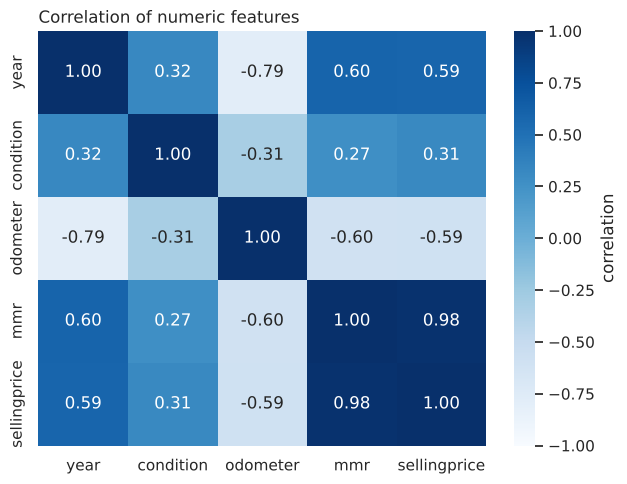

              year  condition  odometer   mmr  sellingprice
year          1.00       0.32     -0.79  0.60          0.59
condition     0.32       1.00     -0.31  0.27          0.31
odometer     -0.79      -0.31      1.00 -0.60         -0.59
mmr           0.60       0.27     -0.60  1.00          0.98
sellingprice  0.59       0.31     -0.59  0.98          1.00

Correlation with selling price:
mmr          0.984
year         0.587
condition    0.313
odometer    -0.592
Name: sellingprice, dtype: float64


In [24]:
num = ['year', 'condition', 'odometer', 'mmr', 'sellingprice']
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1, ax=ax, cbar_kws={'label': 'correlation'})
ax.set_title('Correlation of numeric features', loc='left'); plt.tight_layout(); plt.show()
print(corr.round(2))
print()
print('Correlation with selling price:')
print(corr['sellingprice'].drop('sellingprice').sort_values(ascending=False).round(3))

- **`mmr` (market value) has a 0.98 correlation with selling price.** Cars sell very close to their market value, so it is the strongest single predictor.
- **Year (+0.59) and odometer (−0.59)** are the next strongest: newer and lower-mileage cars sell for more.
- **Year and odometer are strongly linked to each other (−0.79),** since newer cars have fewer miles. Both carry much the same information about price, so they should not be treated as independent factors.
- **Condition has a weaker link (+0.31).** The condition column mixes two scoring scales (see 3.5), which likely weakens this figure.

### 3.2 Average selling price by year
A **bar chart** is the better choice here: year is a discrete category with exactly one average per value, so bars compare years directly. A scatter plot would suit two continuous variables with many points per x value, which is not the case after averaging.

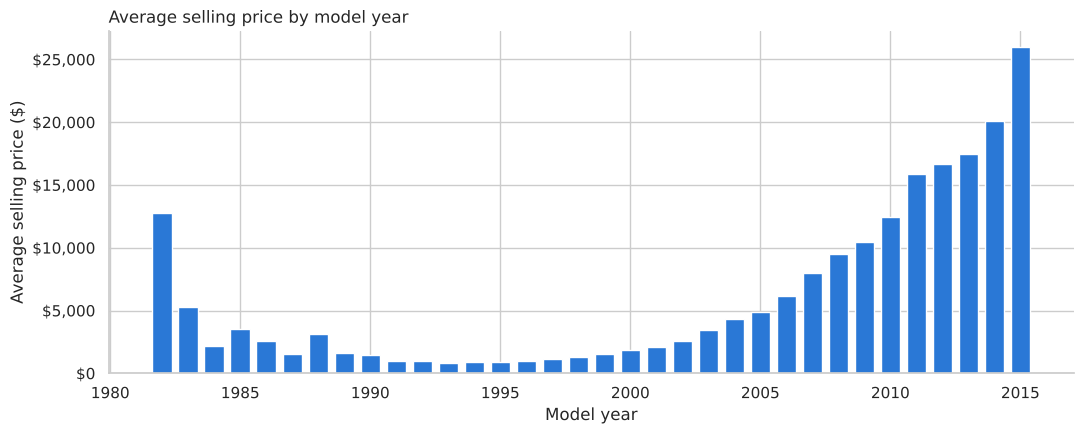

year
1982    12750.0
1983     5250.0
1984     2160.0
1985     3520.0
1986     2539.0
1987     1512.0
1988     3168.0
1989     1620.0
1990     1436.0
1991      944.0
1992      992.0
1993      834.0
1994      871.0
1995      913.0
1996      986.0
1997     1157.0
1998     1262.0
1999     1534.0
2000     1828.0
2001     2131.0
2002     2612.0
2003     3447.0
2004     4321.0
2005     4894.0
2006     6190.0
2007     8022.0
2008     9508.0
2009    10462.0
2010    12412.0
2011    15852.0
2012    16654.0
2013    17477.0
2014    20090.0
2015    25966.0


In [25]:
by_year = df.groupby('year')['sellingprice'].mean()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(by_year.index, by_year.values, color=BLUE, width=0.75)
ax.set_xlabel('Model year'); ax.set_ylabel('Average selling price ($)')
ax.set_title('Average selling price by model year', loc='left')
ax.yaxis.set_major_formatter(lambda v, p: f'${v:,.0f}')
plt.tight_layout(); plt.show()
print(by_year.round(0).to_string())

**A bar chart fits best:** year is a discrete category with one average per value, so bars compare years directly.

**Pattern:** from 1993 onward the average price rises every year, from about **$834 (1993) to $25,966 (2015)**. The steepest rise is at the end: 2013 to 2015 adds about $8,500, and the jump from 2014 ($20,090) to 2015 is about 29%. This is the usual depreciation curve in reverse: the newer the car, the higher the price. The bars for 1982 to 1989 break the pattern (1982 averages $12,750). There are only 68 such cars in total, probably classic or collector cars, so those averages are not reliable.

### 3.3 Average selling price by odometer reading

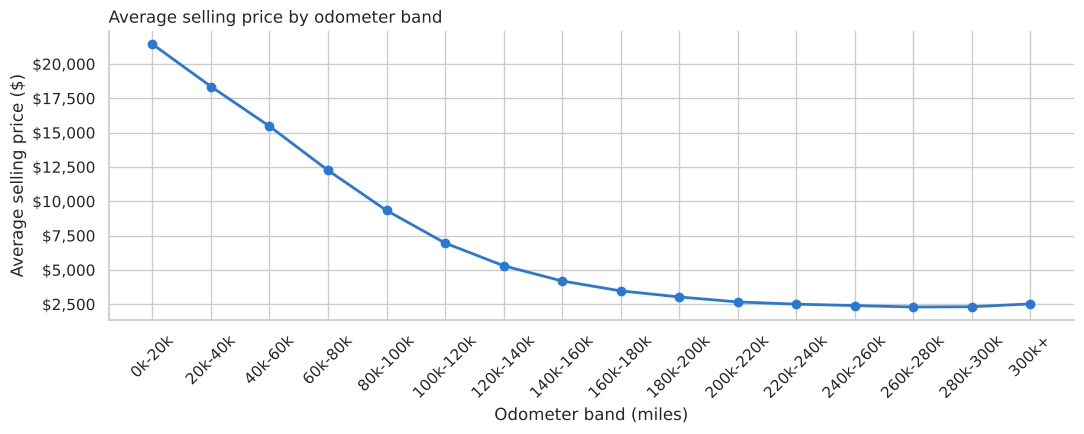

,mean,count
odo_band,,
0k-20k,21445.0,84187
20k-40k,18357.0,137613
40k-60k,15465.0,89347
60k-80k,12252.0,57906
80k-100k,9332.0,52427
100k-120k,6960.0,44159
120k-140k,5306.0,33567
140k-160k,4195.0,23364
160k-180k,3475.0,14946


In [26]:
bins = list(range(0, 300001, 20000)) + [np.inf]
labels = [f'{a//1000}k-{b//1000}k' for a, b in zip(bins[:-2], bins[1:-1])] + ['300k+']
od = df.assign(odo_band=pd.cut(df['odometer'], bins=bins, labels=labels, right=False))
by_odo = od.groupby('odo_band', observed=True)['sellingprice'].agg(['mean', 'count'])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(by_odo.index.astype(str), by_odo['mean'], marker='o', color=BLUE, lw=2)
ax.set_xlabel('Odometer band (miles)'); ax.set_ylabel('Average selling price ($)')
ax.set_title('Average selling price by odometer band', loc='left')
ax.yaxis.set_major_formatter(lambda v, p: f'${v:,.0f}'); plt.xticks(rotation=45)
plt.tight_layout(); plt.show()
by_odo.round(0)

**Price falls steadily as mileage rises.** The average drops from **$21,445 in the 0 to 20k band to $9,332 at 80 to 100k**, a fall of about 56%, and it keeps dropping by roughly 20 to 25% for each further 20k miles up to 160k. After about 220k miles the curve flattens at **roughly $2,300 to $2,500**, which looks like a floor for very old cars. The small rise in the 300k+ band rests on only 672 cars and is noise. Most sales happen in the 20 to 40k band (137,613 cars).

### 3.4 Cars sold per state

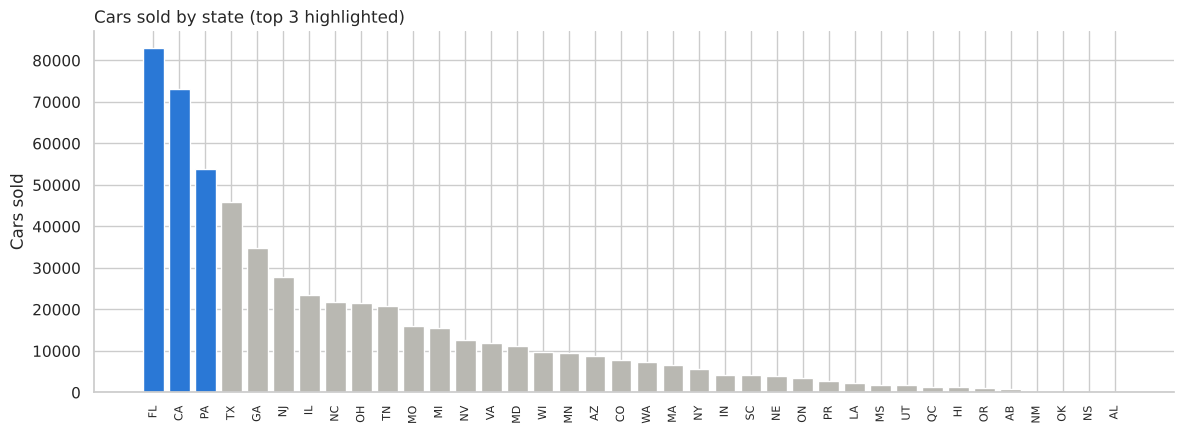

Top three states:
state
fl    82945
ca    73148
pa    53907
Name: cars_sold, dtype: Int64
Their share of all sales: 37.6%


In [27]:
by_state = df['state'].value_counts()
top3 = by_state.head(3)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(by_state.index.str.upper(), by_state.values, color=[BLUE if s in top3.index else GREY for s in by_state.index])
ax.set_ylabel('Cars sold'); ax.set_title('Cars sold by state (top 3 highlighted)', loc='left')
plt.xticks(rotation=90, fontsize=8); plt.tight_layout(); plt.show()
print('Top three states:'); print(top3.rename('cars_sold'))
print('Their share of all sales: {:.1%}'.format(top3.sum() / len(df)))

The top three states are **Florida (82,945 cars), California (73,148) and Pennsylvania (53,907)**, highlighted in the chart. Together they account for **37.6%** of all sales. The data covers 38 states and provinces, and sales drop off quickly after the top few.

### 3.5 Average selling price by condition range (size 5)

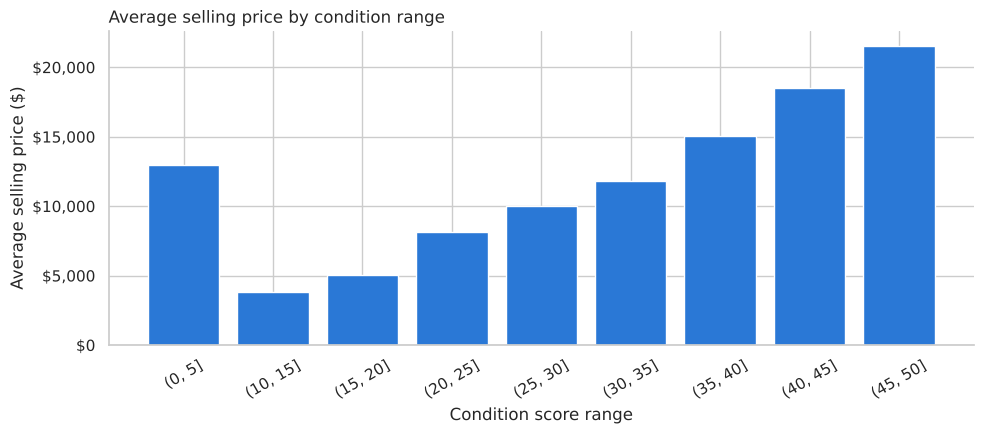

,mean,count
condition,,
"(0, 5]",12987.0,70100
"(10, 15]",3792.0,542
"(15, 20]",5070.0,43020
"(20, 25]",8131.0,45329
"(25, 30]",10037.0,66366
"(30, 35]",11797.0,85744
"(35, 40]",15038.0,87725
"(40, 45]",18494.0,110165
"(45, 50]",21536.0,49808


In [28]:
b5 = pd.cut(df['condition'], bins=range(0, 55, 5), right=True)
p5 = df.groupby(b5, observed=True)['sellingprice'].agg(['mean', 'count'])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(p5.index.astype(str), p5['mean'], color=BLUE)
ax.set_xlabel('Condition score range'); ax.set_ylabel('Average selling price ($)')
ax.set_title('Average selling price by condition range', loc='left')
ax.yaxis.set_major_formatter(lambda v, p: f'${v:,.0f}'); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()
p5.round(0)

- **From a condition of 16 upward, price rises steadily:** from about **$5,070 (16 to 20) to $21,536 (46 to 50)**, roughly four times higher.
- **The 1 to 5 bar is an exception.** It averages $12,987 across 70,100 cars, far above the 11 to 25 bars. The column has no values between 6 and 10: scores are either 1 to 5 or 11 to 49, which suggests **two different grading scales were mixed**. The 1 to 5 cars look like the rest of the fleet (median model year 2012), so they are not truly the worst condition. The trend above should be read within the 11 to 49 range.
- The 11 to 15 bar ($3,792) rests on only 542 cars.

### 3.6 Cars sold by condition range (size 10)

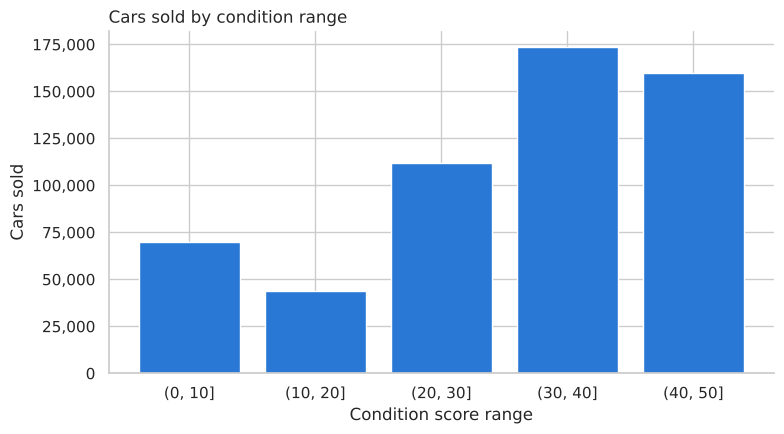

condition
(0, 10]     12.5
(10, 20]     7.8
(20, 30]    20.0
(30, 40]    31.0
(40, 50]    28.6
Name: % of cars, dtype: float64

In [29]:
b10 = pd.cut(df['condition'], bins=range(0, 60, 10), right=True)
c10 = b10.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(c10.index.astype(str), c10.values, color=BLUE)
ax.set_xlabel('Condition score range'); ax.set_ylabel('Cars sold')
ax.set_title('Cars sold by condition range', loc='left')
ax.yaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')
plt.tight_layout(); plt.show()
(c10 / c10.sum() * 100).round(1).rename('% of cars')

- **Most cars are in good condition scores:** the 31 to 40 band is the largest (31.0% of cars) and 41 to 50 is next (28.6%), so almost 60% of cars score above 30.
- **20.0% of cars are in 21 to 30, 12.5% in 1 to 10 and 7.8% in 11 to 20.** The 1 to 10 group is entirely the 1 to 5 scale discussed above. The 11 to 20 group is almost all a single value: 42,276 cars have a condition of exactly 19, which looks like a default score rather than a real inspection.

### 3.7 Selling price distribution by color (box plot)

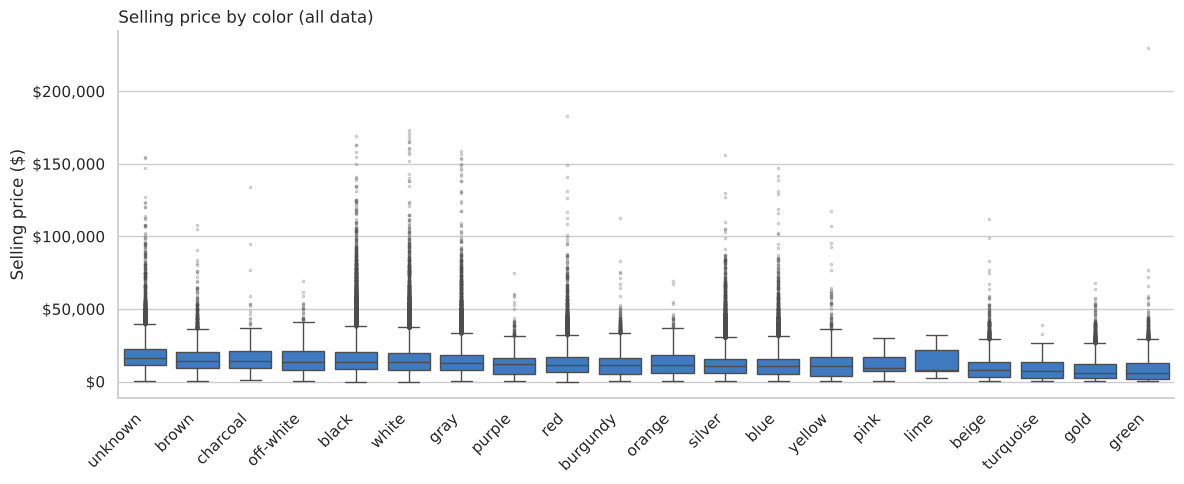

Outliers (1.5 x IQR within each color): 16331 (2.9% of rows)


In [30]:
order = df.groupby('color')['sellingprice'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x='color', y='sellingprice', order=order, color=BLUE, fliersize=1.5, flierprops={'alpha': .3}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('Selling price ($)'); ax.set_title('Selling price by color (all data)', loc='left')
ax.yaxis.set_major_formatter(lambda v, p: f'${v:,.0f}'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()
q1 = df.groupby('color')['sellingprice'].transform(lambda s: s.quantile(.25))
q3 = df.groupby('color')['sellingprice'].transform(lambda s: s.quantile(.75))
iqr = q3 - q1
is_out = (df['sellingprice'] > q3 + 1.5 * iqr) | (df['sellingprice'] < q1 - 1.5 * iqr)
print('Outliers (1.5 x IQR within each color):', is_out.sum(), f'({is_out.mean():.1%} of rows)')

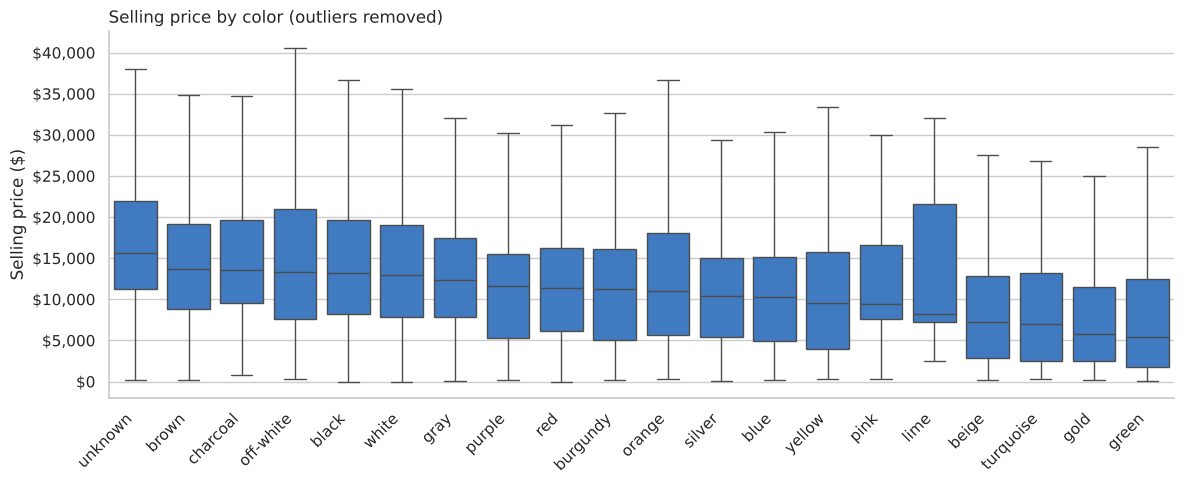

,median,mean,count
color,,,
unknown,15600.0,16825.0,24645
brown,13700.0,14298.0,6494
charcoal,13550.0,14909.0,464
off-white,13350.0,14727.0,1428
black,13200.0,14315.0,107261
white,12900.0,13771.0,103640
gray,12300.0,13006.0,80311
purple,11600.0,11134.0,1515
red,11400.0,11844.0,42333


In [31]:
clean = df[~is_out]
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=clean, x='color', y='sellingprice', order=order, color=BLUE, showfliers=False, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('Selling price ($)'); ax.set_title('Selling price by color (outliers removed)', loc='left')
ax.yaxis.set_major_formatter(lambda v, p: f'${v:,.0f}'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()
clean.groupby('color')['sellingprice'].agg(['median', 'mean', 'count']).round(0).loc[order]

**Before removing outliers:** every color has a tight middle and a long tail of expensive cars (luxury and exotic models), so the whiskers are compressed and the plot is hard to read.

**After removing outliers** (1.5 times the interquartile range within each color, 16,331 rows or 2.9%):
- **Highest medians:** `unknown` ($15,600), brown ($13,700), charcoal ($13,550) and black ($13,200).
- **Lowest medians:** green ($5,400), gold ($5,800), turquoise ($7,000) and beige ($7,300).
- **Common colors are close together:** white $12,900, gray $12,300, red $11,400, silver $10,400, blue $10,300.

Color itself is probably not the driver. Green and gold cars are much older (median model year 2006 and 2007, against 2012 for black and white), and 43% of them are 2005 or older, against 15% of all cars. The `unknown` group is newer than average (2013), which explains its high median.

## Overall summary

- **Data quality:** 26 shifted rows, 12 rows without a price and 72 placeholder odometer readings were fixed, text labels were standardised and the remaining gaps filled. No duplicates were found.
- **Price drivers:** market value (mmr) tracks price almost exactly (0.98). Model year and mileage matter next, and price falls from about $21,400 for cars under 20k miles to about $2,400 beyond 220k.
- **Market structure:** Florida, California and Pennsylvania account for 37.6% of sales, and Ford, Nissan and Toyota models dominate the most-sold list.
- **Cautions:** the `condition` column mixes two scales (1 to 5 and 11 to 49), a few prices and mileages look like entry errors, and color and state differences mostly reflect the age and mix of cars rather than a direct effect.